# Netflix Content Exploratory Data Analysis (EDA)

## Overview
This project explores the Netflix Movies and TV Shows dataset to uncover 
patterns in content type, ratings, genres, countries of production, and 
release trends over time.

## Dataset
Source: [Netflix Movies and TV Shows (Kaggle)](https://www.kaggle.com/datasets/shivamb/netflix-shows)  
8,807 titles with 12 original features including type, director, cast, 
country, date added, rating, duration, and genre.

## Questions Explored
- What is the balance between Movies and TV Shows on the platform?
- How has the volume of content added to Netflix changed over time?
- Which countries produce the most content?
- What content ratings dominate the platform?
- What are the most common genres?
- How does movie duration vary by content rating?

## Tools Used
Python, Pandas, Matplotlib, Seaborn

In [1]:
import pandas as pd 

In [2]:
df = pd.read_csv(r"C:\Users\ARIO\Documents\22 ML project\Exploratory Data Analysis (EDA) Portfolio\netflix_titles.csv")
df.shape

(8807, 12)

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [6]:
df['director'] = df['director'].fillna('unknown')
df['cast'] = df['cast'].fillna('unknown')
df['country'] = df['country'].fillna('unknown')

In [7]:
df = df.dropna(subset=['rating','duration','date_added']).copy()

In [8]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,unknown,unknown,unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [10]:
df.shape

(8790, 12)

In [11]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')

In [12]:
df['date_added'] = pd.to_datetime(df['date_added'])
df['date_added'].dtype

dtype('<M8[ns]')

In [13]:
df['date_added'].isnull().sum()

np.int64(0)

In [14]:
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

In [15]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9
1,s2,TV Show,Blood & Water,unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9
3,s4,TV Show,Jailbirds New Orleans,unknown,unknown,unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,9
4,s5,TV Show,Kota Factory,unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,9


In [16]:
df['type'].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [17]:
df['duration_minutes'] = df[df['type'] == 'Movie']['duration'].str.replace(' min', '').astype(int)
df['duration_seasons'] = df[df['type'] == 'TV Show']['duration'].str.extract('(\d+)').astype(float)

In [18]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,duration_minutes,duration_seasons
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9,90.0,NaN
1,s2,TV Show,Blood & Water,unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,NaN,2.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9,NaN,1.0
3,s4,TV Show,Jailbirds New Orleans,unknown,unknown,unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,9,NaN,1.0
4,s5,TV Show,Kota Factory,unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,9,NaN,2.0


In [19]:
df[['type', 'duration', 'duration_minutes', 'duration_seasons']].head(10)

,type,duration,duration_minutes,duration_seasons
0,Movie,90 min,90.0,NaN
1,TV Show,2 Seasons,NaN,2.0
2,TV Show,1 Season,NaN,1.0
3,TV Show,1 Season,NaN,1.0
4,TV Show,2 Seasons,NaN,2.0
5,TV Show,1 Season,NaN,1.0
6,Movie,91 min,91.0,NaN
7,Movie,125 min,125.0,NaN
8,TV Show,9 Seasons,NaN,9.0
9,Movie,104 min,104.0,NaN


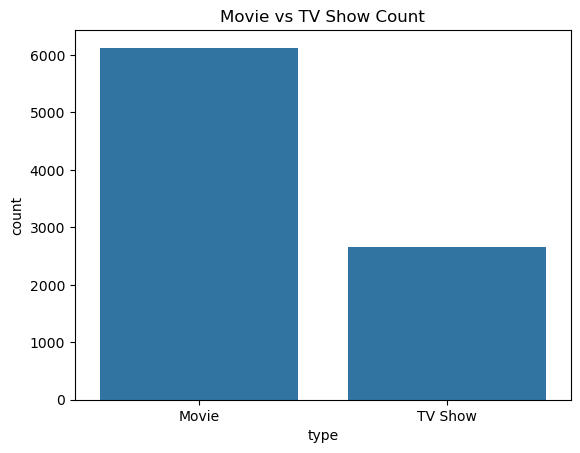

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='type')
plt.title('Movie vs TV Show Count')
plt.show()

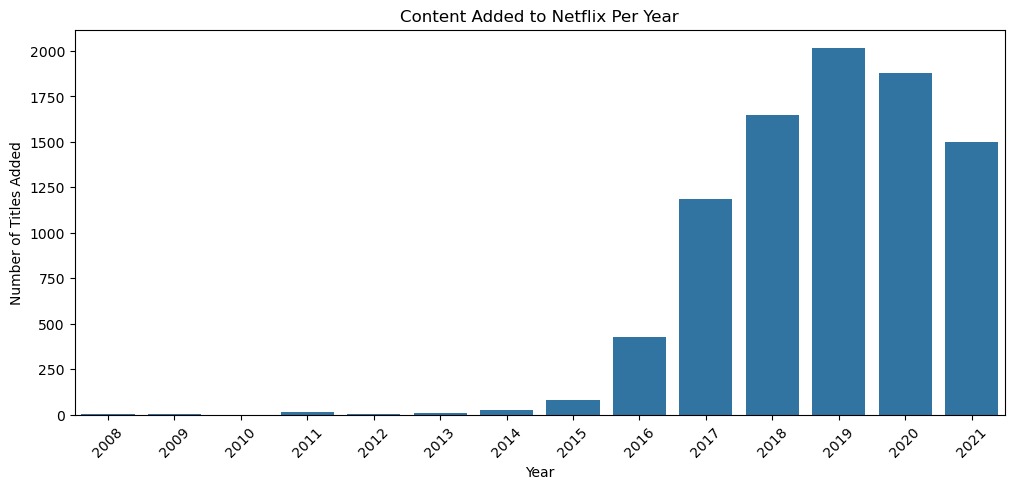

In [21]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='year_added', order=sorted(df['year_added'].dropna().unique()))
plt.title('Content Added to Netflix Per Year')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')
plt.xticks(rotation=45)
plt.show()

In [22]:
df[df['year_added'] == 2021]['month_added'].value_counts().sort_index()

month_added
1    132
2    109
3    112
4    188
5    132
6    207
7    257
8    178
9    183
Name: count, dtype: int64

In [30]:
df['country'].value_counts().head(10)

country
United States     2809
India              972
unknown            829
United Kingdom     418
Japan              243
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64

In [32]:
df['country'].str.split(', ').explode().value_counts().head(100)

country
United States     3680
India             1046
unknown            829
United Kingdom     803
Canada             445
                  ... 
Mozambique           1
Albania              1
United States,       1
Malawi               1
Paraguay             1
Name: count, Length: 100, dtype: int64

In [36]:
countries = df['country'].str.split(',').explode().str.strip()
countries.value_counts().head(100)

country
United States     3681
India             1046
unknown            829
United Kingdom     805
Canada             445
                  ... 
Puerto Rico          1
Mozambique           1
Albania              1
Bermuda              1
Slovakia             1
Name: count, Length: 100, dtype: int64

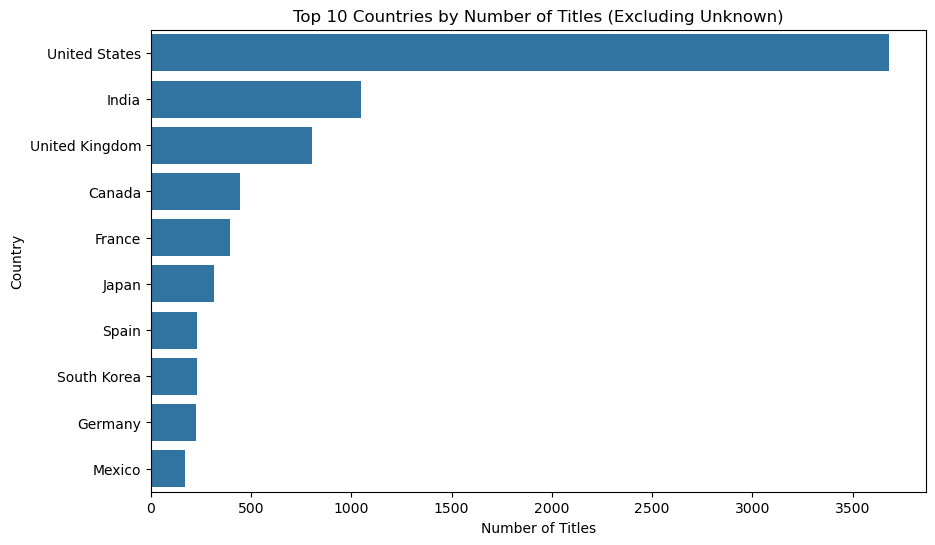

In [38]:
plt.figure(figsize=(10, 6))
top_countries = countries[countries != 'unknown'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 10 Countries by Number of Titles (Excluding Unknown)')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

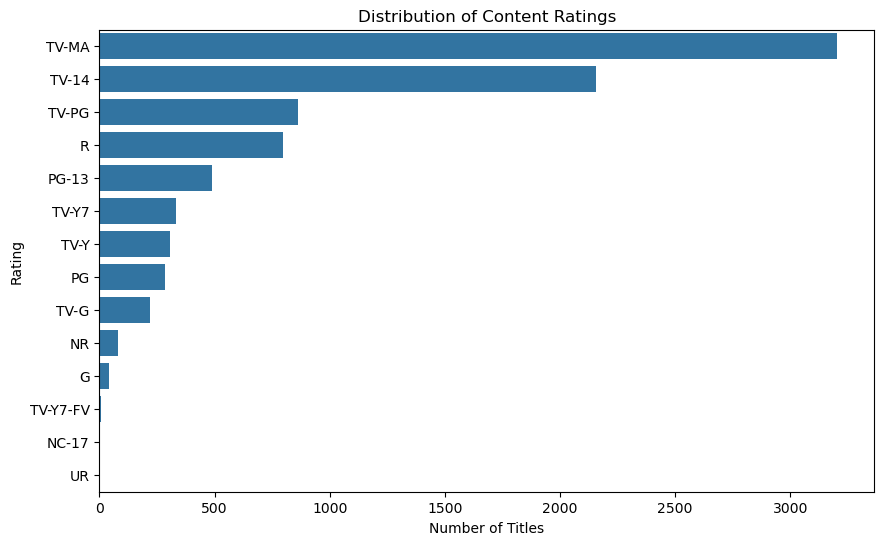

In [39]:
plt.figure(figsize=(10, 6))
order = df['rating'].value_counts().index
sns.countplot(data=df, y='rating', order=order)
plt.title('Distribution of Content Ratings')
plt.xlabel('Number of Titles')
plt.ylabel('Rating')
plt.show()

In [46]:
genres = df['listed_in'].str.split(',').explode().str.strip()
geners.value_counts().head(10)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

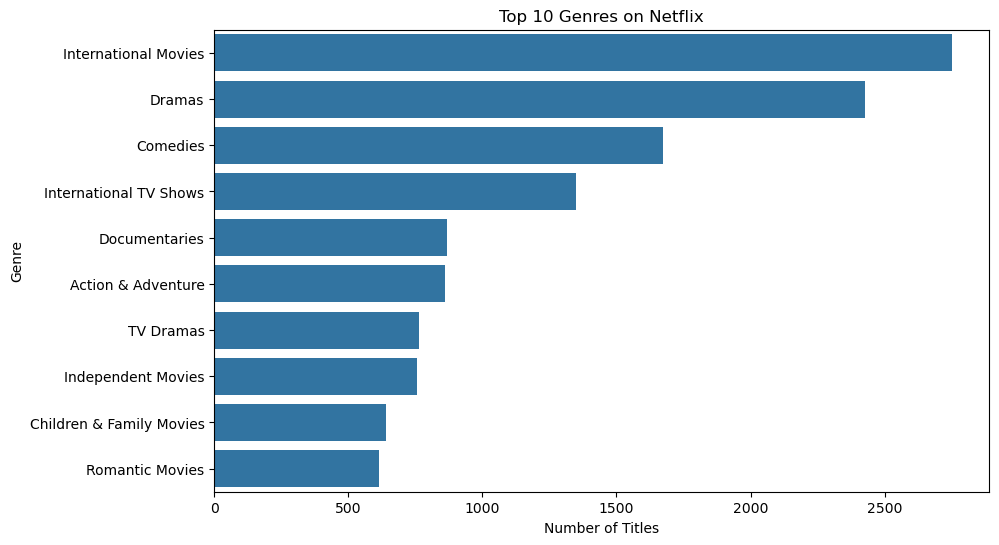

In [47]:
plt.figure(figsize=(10, 6))
top_genres = genres.value_counts().head(10)
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

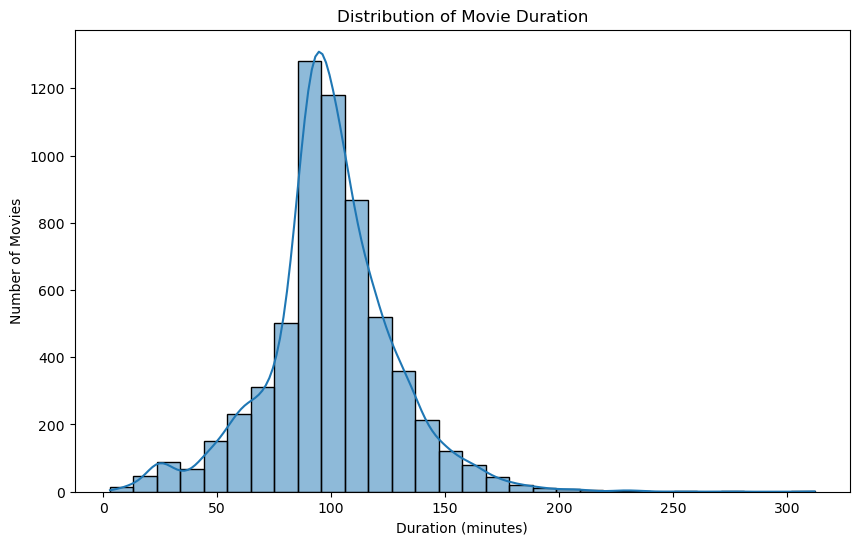

In [48]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='duration_minutes', bins=30, kde=True)
plt.title('Distribution of Movie Duration')
plt.xlabel('Duration (minutes)')
plt.ylabel('Number of Movies')
plt.show()

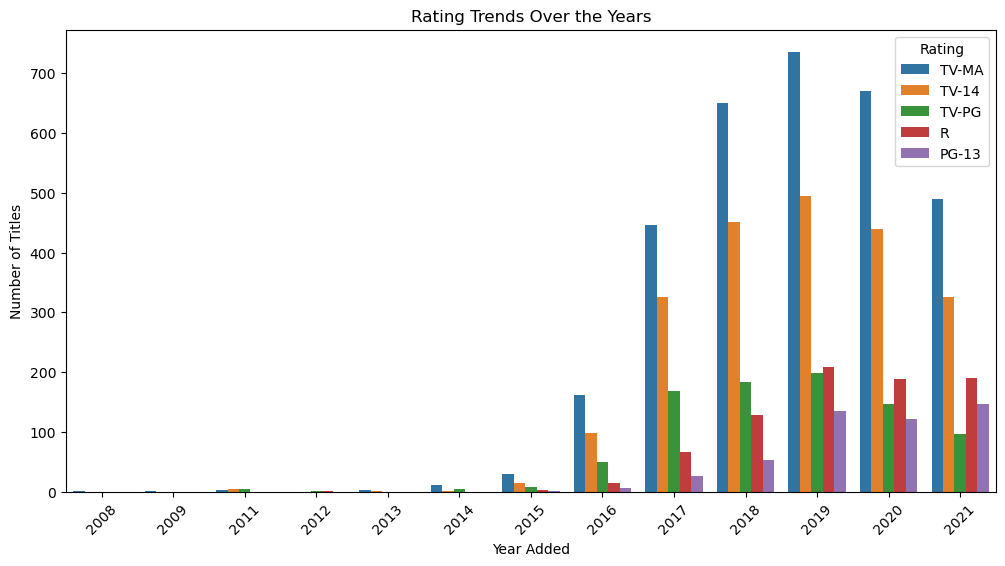

In [49]:
top_ratings = df['rating'].value_counts().head(5).index
df_top_ratings = df[df['rating'].isin(top_ratings)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_top_ratings, x='year_added', hue='rating', 
              order=sorted(df_top_ratings['year_added'].dropna().unique()))
plt.title('Rating Trends Over the Years')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.legend(title='Rating')
plt.show()

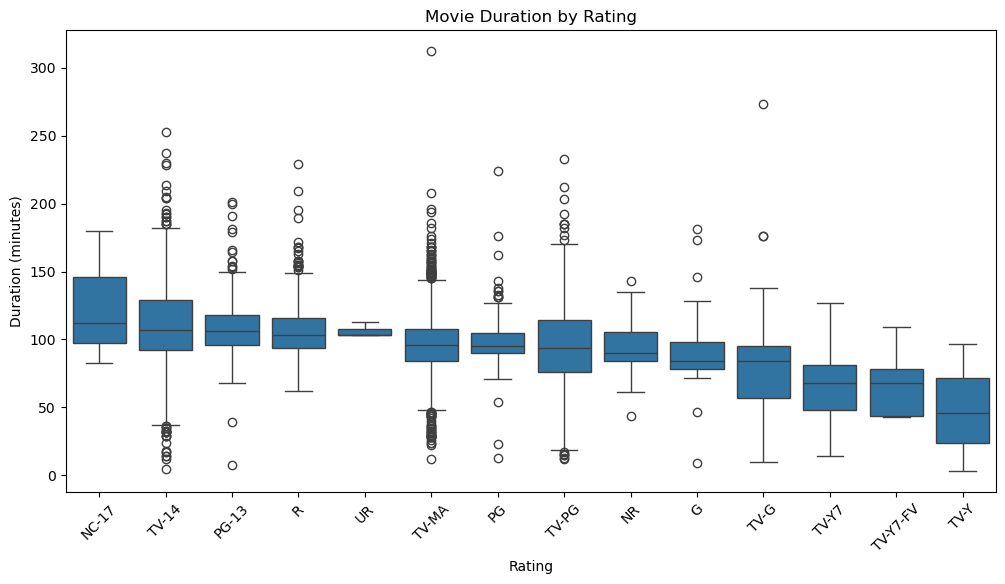

In [50]:
plt.figure(figsize=(12, 6))
movies_df = df[df['type'] == 'Movie']
order = movies_df.groupby('rating')['duration_minutes'].median().sort_values(ascending=False).index
sns.boxplot(data=movies_df, x='rating', y='duration_minutes', order=order)
plt.title('Movie Duration by Rating')
plt.xlabel('Rating')
plt.ylabel('Duration (minutes)')
plt.xticks(rotation=45)
plt.show()

## Key Findings

1. **Content type:** Netflix's library is dominated by Movies (~70%) 
   over TV Shows (~30%).

2. **Growth trend:** Content additions grew steadily from 2015 to 2019, 
   peaking in 2019. The apparent drop in 2021 is misleading — the dataset 
   only covers content added through September 2021, not a real decline.

3. **Top producing country:** The United States leads by a wide margin 
   (3,681 titles), followed by India (1,046) and the United Kingdom (805).

4. **Ratings:** TV-MA is the most common content rating, indicating 
   Netflix's library skews toward adult audiences, with this pattern 
   remaining consistent across years.

5. **Genres:** International Movies is the most frequent genre tag, 
   reflecting Netflix's global content strategy, followed by Dramas 
   and Comedies.

6. **Duration patterns:** Most movies run 90–100 minutes. Adult-rated 
   content (NC-17, R, TV-MA) tends to run longer than children's content 
   (TV-Y, TV-Y7), likely due to differences in genre composition.

## Data Cleaning Notes
- Missing values in `director`, `cast`, and `country` were filled with 
  "Unknown" rather than dropped, preserving ~96% of the